Introduction:
In this project, I will explore factors that may be associated with community college student transfer outcomes. I will examine student GPA, completed college units, weekly study hours, and tutoring participation to better understand how these variables relate to transfer success.
Research Question:
What factors are associated with community college students successfully transferring to a four-year university?
Data Analysis:
I will use Python to calculate averages, compare proportions, and apply concepts from statistics, probability, random sampling, and hypothesis testing to investigate patterns in student outcomes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Student Transfer Prediction Project")
print("Libraries imported successfully!")

Student Transfer Prediction Project
Libraries imported successfully!


In [2]:

# Create a simulated student dataset
np.random.seed(42)

num_students = 1200

students = pd.DataFrame({
    "GPA": np.round(np.random.uniform(2.0, 4.0, num_students), 2),
    "Units_Completed": np.random.randint(12, 75, num_students),
    "Study_Hours": np.random.randint(5, 31, num_students),
    "Tutoring": np.random.choice(["Yes", "No"], num_students)
})

# Simulate transfer outcomes
score = (
    1.5 * students["GPA"]
    + 0.04 * students["Units_Completed"]
    + 0.03 * students["Study_Hours"]
    + np.where(students["Tutoring"] == "Yes", 0.5, 0)
)

probability = 1 / (1 + np.exp(-(score - 7)))

students["Transferred"] = np.where(
    np.random.random(num_students) < probability,
    "Yes",
    "No"
)

students.head()


,GPA,Units_Completed,Study_Hours,Tutoring,Transferred
0,2.75,72,23,No,No
1,3.90,23,15,No,Yes
2,3.46,18,30,No,No
3,3.20,40,9,No,Yes
4,2.31,22,9,Yes,No


In [3]:

# Count how many students transferred
transfer_counts = students["Transferred"].value_counts()

print("Student Transfer Outcomes:")
print(transfer_counts)

# Calculate transfer percentages
transfer_rates = students["Transferred"].value_counts(normalize=True) * 100

print("\nTransfer Percentages:")
print(transfer_rates.round(2))


Student Transfer Outcomes:
Transferred
No     610
Yes    590
Name: count, dtype: int64

Transfer Percentages:
Transferred
No     50.83
Yes    49.17
Name: proportion, dtype: float64


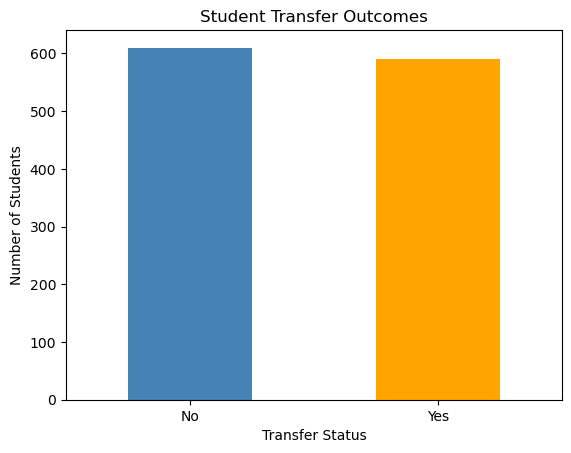

In [4]:

# Visualize student transfer outcomes
transfer_counts.plot(
    kind="bar",
    color=["steelblue", "orange"]
)

plt.title("Student Transfer Outcomes")
plt.xlabel("Transfer Status")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()


Average GPA by Transfer Status:
Transferred
No     2.78
Yes    3.22
Name: GPA, dtype: float64


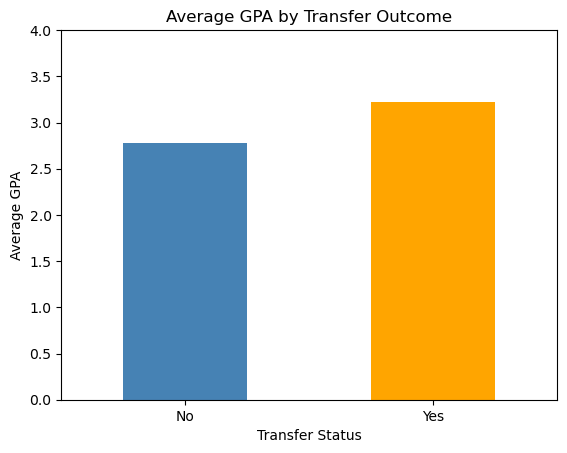

In [5]:

# Calculate average GPA by transfer outcome
average_gpa = students.groupby("Transferred")["GPA"].mean()

print("Average GPA by Transfer Status:")
print(average_gpa.round(2))

# Create a graph
average_gpa.plot(kind="bar", color=["steelblue", "orange"])

plt.title("Average GPA by Transfer Outcome")
plt.xlabel("Transfer Status")
plt.ylabel("Average GPA")
plt.xticks(rotation=0)
plt.ylim(0, 4)
plt.show()


Average Weekly Study Hours:
Transferred
No     17.40
Yes    17.94
Name: Study_Hours, dtype: float64


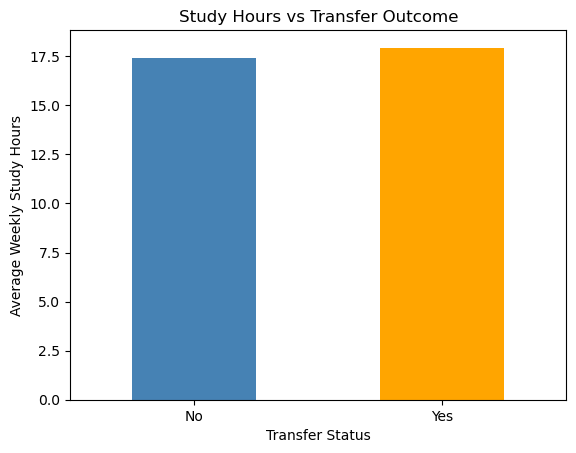

In [6]:

# Compare average study hours by transfer outcome
average_hours = students.groupby("Transferred")["Study_Hours"].mean()

print("Average Weekly Study Hours:")
print(average_hours.round(2))

# Create a graph
average_hours.plot(kind="bar", color=["steelblue", "orange"])

plt.title("Study Hours vs Transfer Outcome")
plt.xlabel("Transfer Status")
plt.ylabel("Average Weekly Study Hours")
plt.xticks(rotation=0)
plt.show()


In [15]:

# Install scikit-learn if needed in JupyterLite
%pip install -q scikit-learn

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Select the information used to make predictions
X = students[["GPA", "Units_Completed",
              "Study_Hours", "Tutoring"]].copy()

# Convert tutoring answers into numbers
X["Tutoring"] = X["Tutoring"].map({"Yes": 1, "No": 0})

# Select the outcome we want to predict
y = students["Transferred"].map({"Yes": 1, "No": 0})

# Divide data into training and testing groups
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create and train the model
model = LogisticRegression(max_iter=2000)
model.fit(X_train, y_train)

# Make predictions
predictions = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, predictions)

print("Model Accuracy:", round(accuracy * 100, 2), "%")


Model Accuracy: 75.42 %


In [9]:

# Randomly sample 100 students
sample = students.sample(n=100, random_state=42)

# Calculate transfer proportions
population_proportion = np.mean(
    students["Transferred"] == "Yes"
)

sample_proportion = np.mean(
    sample["Transferred"] == "Yes"
)

print("Full Dataset Transfer Rate:",
      np.round(population_proportion * 100, 2), "%")

print("Sample Transfer Rate:",
      np.round(sample_proportion * 100, 2), "%")


Full Dataset Transfer Rate: 49.17 %
Sample Transfer Rate: 52.0 %


Average Sample Transfer Rate: 48.92 %


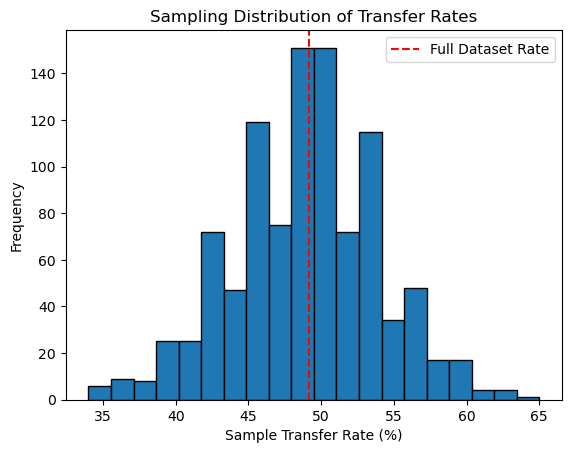

In [10]:

# Simulate 1,000 random samples
sample_proportions = make_array() if "make_array" in globals() else []

for i in range(1000):
    sample = students.sample(n=100, replace=True)
    proportion = np.mean(sample["Transferred"] == "Yes")
    sample_proportions = np.append(sample_proportions, proportion)

# Calculate the average sample proportion
print("Average Sample Transfer Rate:",
      np.round(np.mean(sample_proportions) * 100, 2), "%")

# Visualize the simulation
plt.hist(sample_proportions * 100, bins=20, edgecolor="black")
plt.axvline(population_proportion * 100,
            color="red", linestyle="--",
            label="Full Dataset Rate")

plt.title("Sampling Distribution of Transfer Rates")
plt.xlabel("Sample Transfer Rate (%)")
plt.ylabel("Frequency")
plt.legend()
plt.show()


In [11]:

from sklearn.metrics import confusion_matrix, classification_report

# Compare actual outcomes with predictions
cm = confusion_matrix(y_test, predictions)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["Did Not Transfer", "Transferred"]
))


Confusion Matrix:
[[92 30]
 [29 89]]

Classification Report:
                  precision    recall  f1-score   support

Did Not Transfer       0.76      0.75      0.76       122
     Transferred       0.75      0.75      0.75       118

        accuracy                           0.75       240
       macro avg       0.75      0.75      0.75       240
    weighted avg       0.75      0.75      0.75       240



In [12]:

# Compare completed units by transfer outcome
average_units = students.groupby("Transferred")["Units_Completed"].mean()

print("Average Completed Units:")
print(np.round(average_units, 2))

# Compare the two groups
difference = average_units["Yes"] - average_units["No"]

print("Difference:", np.round(difference, 2), "units")


Average Completed Units:
Transferred
No     36.65
Yes    47.73
Name: Units_Completed, dtype: float64
Difference: 11.08 units


In [13]:

# Separate students by tutoring participation
tutoring_yes = students[students["Tutoring"] == "Yes"]
tutoring_no = students[students["Tutoring"] == "No"]

# Calculate transfer proportions
rate_yes = np.mean(tutoring_yes["Transferred"] == "Yes")
rate_no = np.mean(tutoring_no["Transferred"] == "Yes")

print("Transfer Rate With Tutoring:",
      np.round(rate_yes * 100, 2), "%")

print("Transfer Rate Without Tutoring:",
      np.round(rate_no * 100, 2), "%")

print("Difference:",
      np.round((rate_yes - rate_no) * 100, 2),
      "percentage points")


Transfer Rate With Tutoring: 54.83 %
Transfer Rate Without Tutoring: 43.29 %
Difference: 11.53 percentage points


Observed Difference: 11.53 percentage points
P-value: 0.0


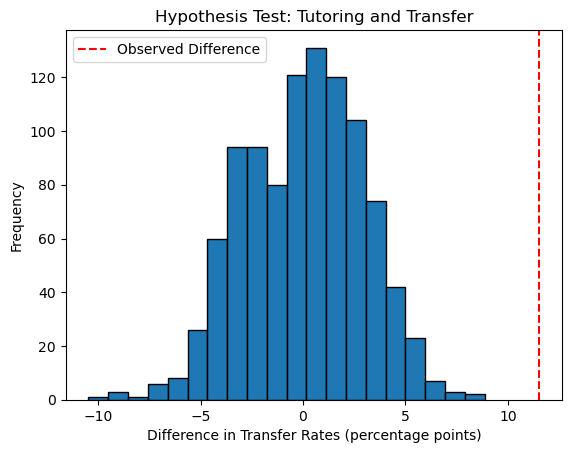

In [14]:

# Observed difference in transfer rates
observed_difference = rate_yes - rate_no

# Simulate the null hypothesis
simulated_differences = []

for i in range(1000):
    shuffled = np.random.permutation(students["Transferred"])

    yes_group = shuffled[students["Tutoring"] == "Yes"]
    no_group = shuffled[students["Tutoring"] == "No"]

    difference = np.mean(yes_group == "Yes") - np.mean(no_group == "Yes")

    simulated_differences = np.append(
        simulated_differences, difference
    )

# Calculate p-value
p_value = np.mean(
    simulated_differences >= observed_difference
)

print("Observed Difference:",
      np.round(observed_difference * 100, 2),
      "percentage points")

print("P-value:", np.round(p_value, 4))

# Visualize the results
plt.hist(simulated_differences * 100, bins=20, edgecolor="black")
plt.axvline(observed_difference * 100,
            color="red", linestyle="--",
            label="Observed Difference")

plt.title("Hypothesis Test: Tutoring and Transfer")
plt.xlabel("Difference in Transfer Rates (percentage points)")
plt.ylabel("Frequency")
plt.legend()
plt.show()


Project Conclusion

This project explored factors associated with community college student transfer outcomes using a simulated dataset of 1,200 students.

Key Findings

GPA: Students who transferred had an average GPA of 3.22 compared with 2.78 for students who did not transfer.
Completed Units: Students who transferred completed approximately 11.08 more units on average.
Study Hours: Students who transferred studied approximately 0.54 more hours per week.
Tutoring: Students who participated in tutoring had a transfer rate of 54.83%, compared with 43.29% for students who did not participate.

Statistical Analysis

I used Python, NumPy, random sampling, and simulation to analyze relationships between student characteristics and transfer outcomes.

A permutation test with 1,000 simulations produced no differences as large as the observed tutoring difference of 11.53 percentage points. This suggests a statistically significant association within the simulated dataset under the test's assumptions.

Limitations

All student records were simulated rather than collected from real institutions. The results reflect the assumptions used to generate the data and cannot establish real-world relationships or causation.

What I Learned

This project helped me apply concepts from my Data Science coursework, including probability, sampling distributions, hypothesis testing, data visualization, and statistical analysis.